## Libraries

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
from scipy import stats
import seaborn as sns

## Inputs and Outputs

In [6]:
### INPUT ###
conc_path = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Data\AVP2016_concentrations_data.xlsx"
conc_data = pd.read_excel(conc_path)

In [7]:
### OUTPUT ###
output_dir = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Results"

## Dataframe

In [9]:
rows = len(conc_data['date'])-3   # -3 because the columns include 3 NaN values on the bottom rows otherwise.

data = {
    "POC": conc_data['POC'][:rows],              # umol/L
    "TOC": conc_data['TOC'][:rows],              # umol/L
    "PON": conc_data['PON'][:rows],              # umol/L
    "POP": conc_data['POP'][:rows],              # umol/L
    "date": conc_data['date'][:rows]
}

df = pd.DataFrame(data)
# print(df)

## Plots

## Main

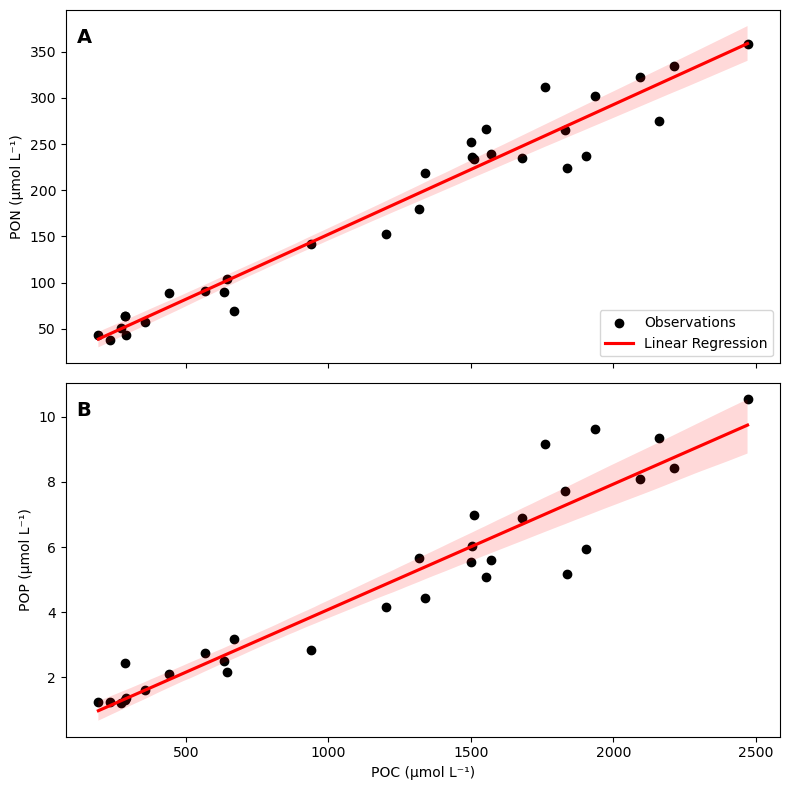

In [24]:
fig, axs = plt.subplots(2, 1, sharex=True, figsize=(8,8))

axs[0].scatter(df['POC'], df['PON'], label='Observations', color='black')
sns.regplot(data=df, x='POC', y='PON', ax=axs[0], scatter=False, color='red', ci=95, label='Linear Regression')
axs[0].set_ylabel('PON (µmol L⁻¹)')
axs[0].set_xlabel('')
axs[0].legend()



axs[1].scatter(df['POC'], df['POP'], label='Observations', color='black')
sns.regplot(data=df, x='POC', y='POP', ax=axs[1], scatter=False, color='red', ci=95, label='Linear Regression')
axs[1].set_ylabel('POP (µmol L⁻¹)')
axs[1].set_xlabel('POC (µmol L⁻¹)')


for ax, label in zip(axs.flat, "ABC"):
    ax.text(
        0.015, 0.95, label,
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=14, fontweight="bold"
    )

fig.tight_layout()

############ Saving ############
out = os.path.join(output_dir, "Plots\\nutrient_relations")
plt.savefig(out)
################################


plt.show()

### POC/PON

Linear correlation: 0.9757637435851592
Nonlinear correlation: 0.9483870967741937
Nonparametric correlation: 0.8279569892473119


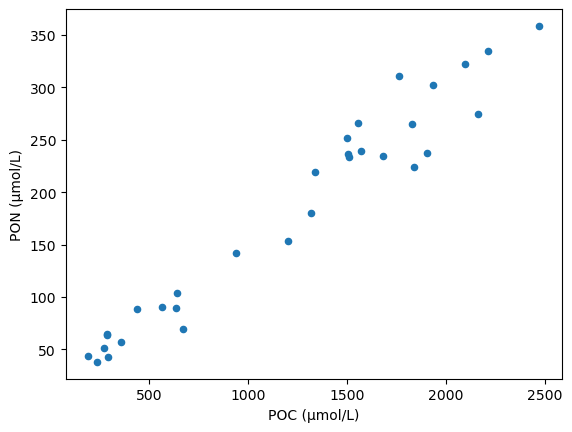

Formula: PON = 11.6064 + 0.1405044 * POC
R² = 0.9521
p-value = 0.0000
 
Formula: POC = -21.1990 + 6.7764085 * PON
R² = 0.9521
p-value = 0.0000


In [44]:
############ Correlations ############
lin_cor = df['POC'].corr(df['PON'])                         # Linear correlation using Pearson's coefficient
nonlin_cor = df['POC'].corr(df['PON'], method='spearman')   # Nonlinear correlation using Spearman's rank coefficient
nonpara_cor = df['POC'].corr(df['PON'], method='kendall')   # Nonparametric measure using Kendall's Tau correlation coefficient

print(f'Linear correlation: {lin_cor}')
print(f'Nonlinear correlation: {nonlin_cor}')
print(f'Nonparametric correlation: {nonpara_cor}')

############ Plotting ############
plot = df.plot(kind='scatter', x='POC', y='PON')
plot.set_xlabel('POC (µmol/L)')
plot.set_ylabel('PON (µmol/L)')
# plt.title("...")

############ Saving ############
out = os.path.join(output_dir, "Plots\\PON-POC_relation")
plt.savefig(out)

plt.show()

############ linear regression ############
slope, intercept, r_value, p_value, std_err = stats.linregress(df['POC'].values, df['PON'].values)

print(f"Formula: PON = {intercept:.4f} + {slope:.7f} * POC")
print(f"R² = {r_value**2:.4f}")
print(f"p-value = {p_value:.4f}")

print(" ")

slope, intercept, r_value, p_value, std_err = stats.linregress(df['PON'].values, df['POC'].values)

print(f"Formula: POC = {intercept:.4f} + {slope:.7f} * PON")
print(f"R² = {r_value**2:.4f}")
print(f"p-value = {p_value:.4f}")

In [16]:
PON = df['PON'].values
POC = df['POC'].values

PON_POC = np.sum(POC * PON) / np.sum(POC**2)
POC_PON = np.sum(PON * POC) / np.sum(PON**2)

print(f'PON/POC ratio: {PON_POC}')
print(f'POC/PON ratio: {POC_PON}')

PON/POC ratio: 0.14770923587022305
POC/PON ratio: 6.686939532289969


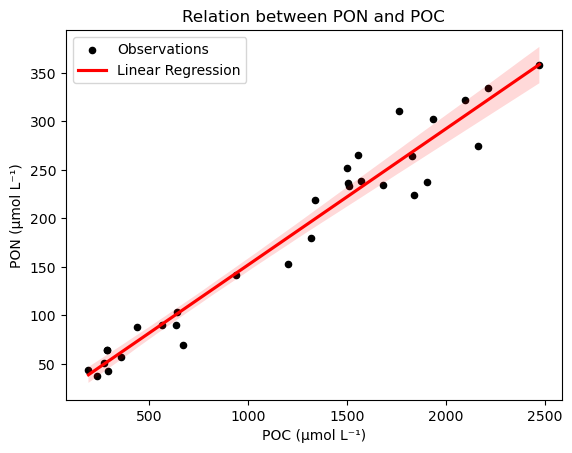

In [27]:
# lin_cor = df['SA'].corr(df['POC'])                         # Linear correlation using Pearson's coefficient
# print(f'Linear correlation: {lin_cor}')

### Plotting ###
plot = df.plot(kind='scatter',x='POC', y='PON', label='Observations', color='black')

sns.regplot(data=df, x='POC', y='PON', ax=plot, scatter=False, color='red', ci=95, label='Linear Regression')

plot.set_ylabel('PON (µmol L⁻¹)')
plot.set_xlabel('POC (µmol L⁻¹)')
# plt.title("Relation between PON and POC")
plot.legend()

############ Saving ############
out = os.path.join(output_dir, "Plots\\PON-POC_relation")
plt.savefig(out)
################################

plt.show()

### TOC/PON

Linear correlation: 0.9735057809195571
Nonlinear correlation: 0.9649193548387097
Nonparametric correlation: 0.853763440860215


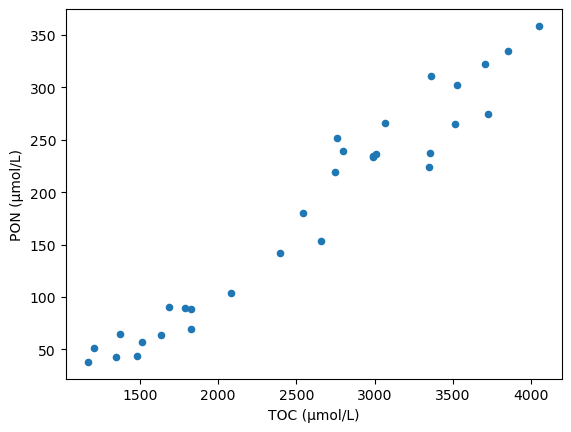

Formula: PON = -108.0046 + 0.1127 * TOC
R² = 0.9477
p-value = 0.0000
 
Formula: TOC = 1042.3840 + 8.4128 * PON
R² = 0.9477
p-value = 0.0000


In [46]:
############ Correlations ############
lin_cor = df['TOC'].corr(df['PON'])                         # Linear correlation using Pearson's coefficient
nonlin_cor = df['TOC'].corr(df['PON'], method='spearman')   # Nonlinear correlation using Spearman's rank coefficient
nonpara_cor = df['TOC'].corr(df['PON'], method='kendall')   # Nonparametric measure using Kendall's Tau correlation coefficient

print(f'Linear correlation: {lin_cor}')
print(f'Nonlinear correlation: {nonlin_cor}')
print(f'Nonparametric correlation: {nonpara_cor}')

############ Plotting ############
plot = df.plot(kind='scatter', x='TOC', y='PON')
plot.set_xlabel('TOC (µmol/L)')
plot.set_ylabel('PON (µmol/L)')
# plt.title("...")

############ Saving ############
out = os.path.join(output_dir, "Plots\\PON-TOC_relation.png")
plt.savefig(out)

plt.show()

############ linear regression ############
slope, intercept, r_value, p_value, std_err = stats.linregress(df['TOC'].values, df['PON'].values)

print(f"Formula: PON = {intercept:.4f} + {slope:.4f} * TOC")
print(f"R² = {r_value**2:.4f}")
print(f"p-value = {p_value:.4f}")

print(" ")

slope, intercept, r_value, p_value, std_err = stats.linregress(df['PON'].values, df['TOC'].values)

print(f"Formula: TOC = {intercept:.4f} + {slope:.4f} * PON")
print(f"R² = {r_value**2:.4f}")
print(f"p-value = {p_value:.4f}")

In [12]:
PON = df['PON'].values
TOC = df['TOC'].values

PON_TOC = np.sum(TOC * PON) / np.sum(TOC**2)
TOC_PON = np.sum(PON * TOC) / np.sum(PON**2)

print(f'PON/TOC ratio: {PON_TOC}')
print(f'TOC/PON ratio: {TOC_PON}')

PON/TOC ratio: 0.0748442854030245
TOC/PON ratio: 12.812147494324542


### POC/POP

Linear correlation: 0.9497668820457644
Nonlinear correlation: 0.9443548387096774
Nonparametric correlation: 0.8236559139784947


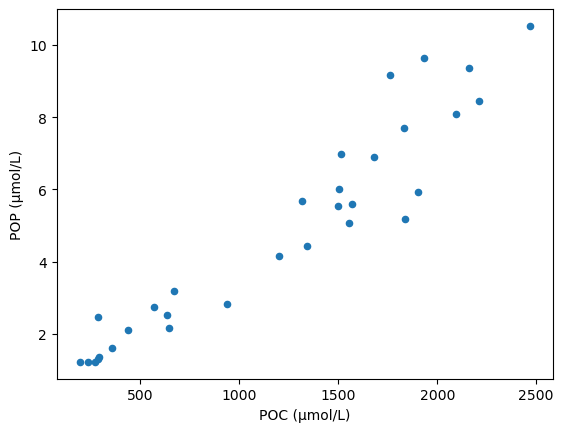

Formula: POP = 0.2296 + 0.0038505 * POC
R² = 0.9021
p-value = 0.0000
 
Formula: POC = 63.7090 + 234.2715689 * POP
R² = 0.9021
p-value = 0.0000


In [48]:
############ Correlations ############
lin_cor = df['POC'].corr(df['POP'])                         # Linear correlation using Pearson's coefficient
nonlin_cor = df['POC'].corr(df['POP'], method='spearman')   # Nonlinear correlation using Spearman's rank coefficient
nonpara_cor = df['POC'].corr(df['POP'], method='kendall')   # Nonparametric measure using Kendall's Tau correlation coefficient

print(f'Linear correlation: {lin_cor}')
print(f'Nonlinear correlation: {nonlin_cor}')
print(f'Nonparametric correlation: {nonpara_cor}')

############ Plotting ############
plot = df.plot(kind='scatter', x='POC', y='POP')
plot.set_xlabel('POC (µmol/L)')
plot.set_ylabel('POP (µmol/L)')
# plt.title("...")

############ Saving ############
out = os.path.join(output_dir, "Plots\\POP-POC_relation.png")
plt.savefig(out)

plt.show()

############ linear regression ############
slope, intercept, r_value, p_value, std_err = stats.linregress(df['POC'].values, df['POP'].values)

print(f"Formula: POP = {intercept:.4f} + {slope:.7f} * POC")
print(f"R² = {r_value**2:.4f}")
print(f"p-value = {p_value:.4f}")

print(" ")

slope, intercept, r_value, p_value, std_err = stats.linregress(df['POP'].values, df['POC'].values)

print(f"Formula: POC = {intercept:.4f} + {slope:.7f} * POP")
print(f"R² = {r_value**2:.4f}")
print(f"p-value = {p_value:.4f}")

In [14]:
POP = df['POP'].values
POC = df['POC'].values

POP_POC = np.sum(POC * POP) / np.sum(POC**2)
POC_POP = np.sum(POP * POC) / np.sum(POP**2)

print(f'POP/POC ratio: {POP_POC}')
print(f'POC/POP ratio: {POC_POP}')

POP/POC ratio: 0.0039930315730454
POC/POP ratio: 244.0411299506745


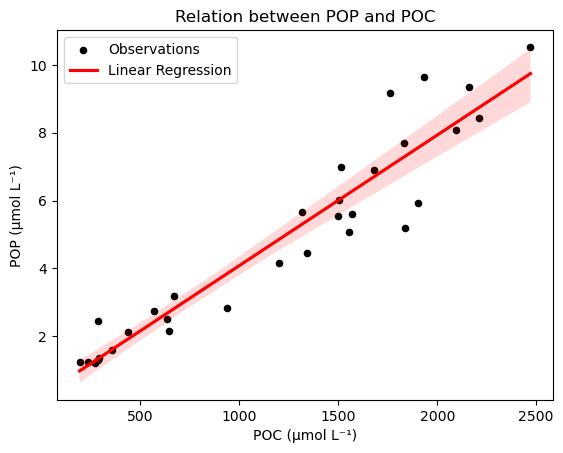

In [31]:
### Plotting ###
plot = df.plot(kind='scatter',x='POC', y='POP', label='Observations', color='black')

sns.regplot(data=df, x='POC', y='POP', ax=plot, scatter=False, color='red', ci=95, label='Linear Regression')

plot.set_ylabel('POP (µmol L⁻¹)')
plot.set_xlabel('POC (µmol L⁻¹)')
plt.title("Relation between POP and POC")
plot.legend()

############ Saving ############
out = os.path.join(output_dir, "Plots\\POP-POC_relation")
plt.savefig(out)
################################

plt.show()

### TOC/POP

Linear correlation: 0.9456281700296144
Nonlinear correlation: 0.9495967741935486
Nonparametric correlation: 0.8150537634408603


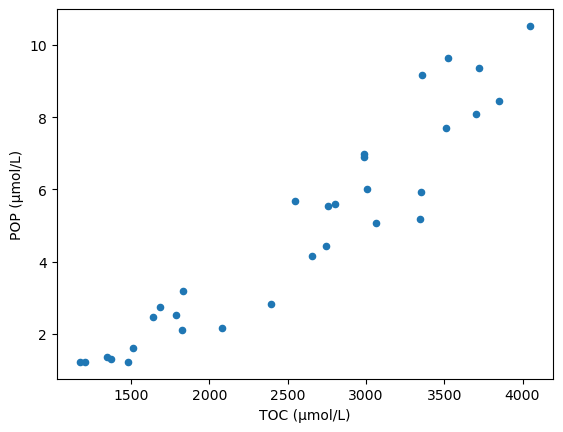

Formula: POP = -3.0321 + 0.0031 * TOC
R² = 0.8942
p-value = 0.0000
 
Formula: TOC = 1150.6853 + 290.2498 * POP
R² = 0.8942
p-value = 0.0000


In [50]:
############ Correlations ############
lin_cor = df['TOC'].corr(df['POP'])                         # Linear correlation using Pearson's coefficient
nonlin_cor = df['TOC'].corr(df['POP'], method='spearman')   # Nonlinear correlation using Spearman's rank coefficient
nonpara_cor = df['TOC'].corr(df['POP'], method='kendall')   # Nonparametric measure using Kendall's Tau correlation coefficient

print(f'Linear correlation: {lin_cor}')
print(f'Nonlinear correlation: {nonlin_cor}')
print(f'Nonparametric correlation: {nonpara_cor}')

############ Plotting ############
plot = df.plot(kind='scatter', x='TOC', y='POP')
plot.set_xlabel('TOC (µmol/L)')
plot.set_ylabel('POP (µmol/L)')
# plt.title("...")

############ Saving ############
out = os.path.join(output_dir, "Plots\\POP-TOC_relation.png")
plt.savefig(out)

plt.show()

############ linear regression ############
slope, intercept, r_value, p_value, std_err = stats.linregress(df['TOC'].values, df['POP'].values)

print(f"Formula: POP = {intercept:.4f} + {slope:.4f} * TOC")
print(f"R² = {r_value**2:.4f}")
print(f"p-value = {p_value:.4f}")

print(" ")

slope, intercept, r_value, p_value, std_err = stats.linregress(df['POP'].values, df['TOC'].values)

print(f"Formula: TOC = {intercept:.4f} + {slope:.4f} * POP")
print(f"R² = {r_value**2:.4f}")
print(f"p-value = {p_value:.4f}")

In [10]:
POP = df['POP'].values
TOC = df['TOC'].values

POP_TOC = np.sum(TOC * POP) / np.sum(TOC**2)
TOC_POP = np.sum(POP * TOC) / np.sum(POP**2)

print(f'POP/TOC ratio: {POP_TOC}')
print(f'TOC/POP ratio: {TOC_POP}')

POP/TOC ratio: 0.0020194692766829217
TOC/POP ratio: 466.70351547443767
